# Gear dynamics 06: flexible shafts

The last step of the series. The gears now sit on **shafts modelled with finite elements**:
bending in two planes plus torsion, bearings as springs at their nodes, an input inertia
(engine side) and an output inertia (load side) at the shaft ends. The same `Model` and the
same mesh element as in notebooks 02–05 couple the two shafts at the gear nodes. Only the
linear structure got bigger.

The four variants are built from the same mesh, with the shaft stiffness scaled:

| variant | torsion | bending | what it isolates |
|---|---|---|---|
| **R** | rigid (×1000) | rigid (×1000) | gears on bearings only (≈ notebook 05) |
| **T** | flexible | rigid | classic torsional drivetrain model |
| **B** | rigid | flexible | shaft bending changes the mesh and the bearing loads |
| **F** | flexible | flexible | everything |

**Contents:** shaft elements and their validation · the drivetrain · statics (bearing
reactions identical to notebook 01, deflections not) · modes · **experiment A**: wind-up
energy released through a mesh with backlash · **experiment B**: running at speed, rigid
against flexible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import geardyn as gd

gd.style()
gp = gd.GearPair(backlash=60e-6)
T1 = 40.0
F0 = T1 / gp.rb1

## 1  Shaft finite elements

Node DOFs: lateral displacements $x, y$, **slopes** $x' = dx/dz,\ y' = dy/dz$ and the torsion
angle $\theta$. Using slopes instead of rotations gives the same Euler–Bernoulli element in
both planes, with no sign bookkeeping:

$$\mathbf K_b = \frac{EI}{L^3}\begin{bmatrix}12 & 6L & -12 & 6L\\ 6L & 4L^2 & -6L & 2L^2\\ -12 & -6L & 12 & -6L\\ 6L & 2L^2 & -6L & 4L^2\end{bmatrix},\qquad
  \mathbf K_t = \frac{GJ_p}{L}\begin{bmatrix}1 & -1\\-1 & 1\end{bmatrix}$$

with consistent mass matrices ($\rho A L/420\,[\dots]$ and $\rho J_p L/6\,[2\ 1; 1\ 2]$).
Gears and discs are rigid bodies at nodes: mass on $x, y$, polar inertia on $\theta$,
diametral inertia on the slopes. Gyroscopic coupling is neglected; it matters for whirl of
fast, overhung discs, which is beyond this series.

**Validation**: a simply supported shaft, against the analytic first bending frequency and
mid-span deflection, and the first free-free torsion mode.

In [2]:
L, d = 0.20, 0.02
mv = gd.Model()
sh = gd.add_shaft(mv, "s", L, d, n_el=12)
kN = len(sh["z"]) - 1
for c in ["x", "y"]:
    mv.add_spring(sh["dof"](0, c), None, 1e14); mv.add_spring(sh["dof"](kN, c), None, 1e14)
EI = 2.1e11 * np.pi * d**4 / 64; rA = 7850 * np.pi * d**2 / 4
f, _ = mv.linear_modes(include_mesh=False)
fb = np.sort(f[f > 1])
print(f"1st bending: FE {fb[0]:.1f} Hz, analytic (pi/L)^2 sqrt(EI/rhoA)/2pi = {(np.pi/L)**2*np.sqrt(EI/rA)/2/np.pi:.1f} Hz")
print(f"2nd bending: FE {fb[2]:.1f} Hz, analytic {(2*np.pi/L)**2*np.sqrt(EI/rA)/2/np.pi:.1f} Hz")
ft = np.sqrt(8.1e10 / 7850) / (2 * L)
print(f"1st free-free torsion: FE {[x for x in fb if abs(x-ft)/ft < 0.05][0]:.0f} Hz, analytic c/(2L) = {ft:.0f} Hz")
_, K, _ = mv.matrices()
Q = np.zeros(mv.n); Q[mv.index(sh["dof"](6, "y"))] = 1000.0
mv.add_spring(sh["dof"](0, "th"), None, 1e14); _, K, _ = mv.matrices()
qq = np.linalg.solve(K, Q)
print(f"mid-span deflection under 1 kN: FE {qq[mv.index(sh['dof'](6,'y'))]*1e6:.2f} um, F L^3/48EI = {1000*L**3/48/EI*1e6:.2f} um")

1st bending: FE 1015.6 Hz, analytic (pi/L)^2 sqrt(EI/rhoA)/2pi = 1015.6 Hz
2nd bending: FE 4062.4 Hz, analytic 4062.2 Hz
1st free-free torsion: FE 8054 Hz, analytic c/(2L) = 8031 Hz
mid-span deflection under 1 kN: FE 101.05 um, F L^3/48EI = 101.05 um


## 2  The drivetrain

Both shafts are 140 mm long, with bearings A at $z = 0$ and B at $z = 80$ mm and the gear at
$z = 25$ mm (the notebook 01 layout). Overhung at $z = 140$ mm: the input inertia on shaft 1
($J_\text{in} = 0.02$ kg m², think crank or clutch side) and the output inertia on shaft 2
($J_\text{out} = 0.05$ kg m²). Shaft diameters are 22 and 28 mm, each bearing 3·10⁸ N/m, and a
little material damping ($C = \beta K$) plus bearing damping. Shaft 2's torsion angle uses the
CW-positive convention of the series, so the mesh element is unchanged.

90 DOFs, nodes on shaft 1 at z = [  0.   23.3  25.   46.7  70.   80.   93.3 116.7 140. ] mm


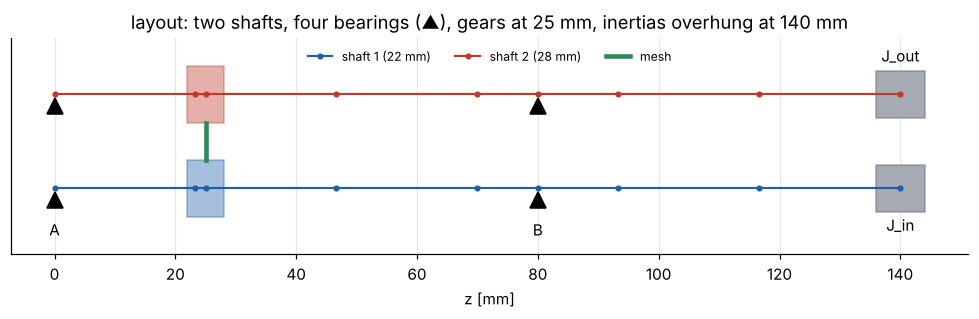

In [3]:
VARIANTS = {"R": (1e3, 1e3), "T": (1e3, 1.0), "B": (1.0, 1e3), "F": (1.0, 1.0)}   # (bend, torsion) scale
kb = 3e8
J_in, J_out = 0.02, 0.05
F_CUT = 20e3


def drivetrain(var, kb=kb, n_el=6, gp=gp, J_in=J_in, J_out=J_out, stiffness="const"):
    bs, ts = VARIANTS[var]
    m = gd.Model(); shafts = []
    for name, dia in [("s1", 0.022), ("s2", 0.028)]:
        shafts.append(gd.add_shaft(m, name, 0.14, dia, n_el=n_el, stations=(0.025, 0.08),
                                   bend_scale=bs, tors_scale=ts, beta=2e-6))
    s1, s2 = shafts
    gd.add_disc(m, s1, 0.025, gp.m1, gp.J1); gd.add_disc(m, s2, 0.025, gp.m2, gp.J2)
    gd.add_disc(m, s1, 0.14, 1.0, J_in); gd.add_disc(m, s2, 0.14, 1.5, J_out)
    for s in shafts:
        for zb, nm in [(0.0, "A"), (0.08, "B")]:
            k = s["node"](zb)
            m.add_bearing(f"{s['name']}{nm}", s["dof"](k, "x"), s["dof"](k, "y"), kb, 2 * 0.03 * np.sqrt(kb * 1.0))
    g1, g2 = s1["node"](0.025), s2["node"](0.025)
    m.add_mesh(gp, s1["dof"](g1, "th"), s2["dof"](g2, "th"),
               x1=s1["dof"](g1, "x"), y1=s1["dof"](g1, "y"),
               x2=s2["dof"](g2, "x"), y2=s2["dof"](g2, "y"), contact="backlash", stiffness=stiffness)
    end1, end2 = s1["dof"](s1["node"](0.14), "th"), s2["dof"](s2["node"](0.14), "th")
    return m, s1, s2, end1, end2


m, s1, s2, end1, end2 = drivetrain("F")
print(f"{m.n} DOFs, nodes on shaft 1 at z = {np.round(s1['z']*1e3, 1)} mm")

fig, ax = plt.subplots(figsize=(9, 3))
for yy, s, col, lab in [(0, s1, gd.C["blue"], "shaft 1 (22 mm)"), (1, s2, gd.C["red"], "shaft 2 (28 mm)")]:
    ax.plot(s["z"] * 1e3, yy + 0 * s["z"], "-o", color=col, ms=3, label=lab)
    for zb in (0, 80):
        ax.plot(zb, yy - 0.12, "^", color="k", ms=10)
    ax.add_patch(plt.Rectangle((22, yy - 0.3), 6, 0.6, color=col, alpha=0.4))
    ax.add_patch(plt.Rectangle((136, yy - 0.25), 8, 0.5, color=gd.C["grey"], alpha=0.6))
ax.plot([25, 25], [0.3, 0.7], color=gd.C["green"], lw=3, label="mesh")
ax.text(140, -0.45, "J_in", ha="center"); ax.text(140, 1.35, "J_out", ha="center")
ax.text(0, -0.5, "A", ha="center"); ax.text(80, -0.5, "B", ha="center")
ax.set_yticks([]); ax.set_xlabel("z [mm]"); ax.set_ylim(-0.7, 1.6); ax.legend(loc="upper center", ncol=3, fontsize=8)
ax.set_title("layout: two shafts, four bearings (▲), gears at 25 mm, inertias overhung at 140 mm")
plt.tight_layout()

## 3  Statics: same reactions, different deflections

Clamp the output end, apply 40 N m at the input end. Because each shaft is statically
determinate, the **bearing reactions do not depend on any stiffness**. They must equal the
notebook 01 hand calculation in every variant. The **deflections** are a different matter.
Each variant stores the preload energy somewhere else. Experiment A releases exactly that
energy.

In [4]:
def strain_split(m, s1, s2, q):
    out = {}
    out["shaft torsion"] = sum(gd.element_energy(m, s, q, "torsion") for s in (s1, s2))
    out["shaft bending"] = sum(gd.element_energy(m, s, q, "bending") for s in (s1, s2))
    out["bearings"] = sum(0.5 * b.k * (q[b.ix]**2 + q[b.iy]**2) for b in m.bearings)
    out["mesh"] = m.meshes[0].evaluate(q, 0 * q)["U"]
    return out


Fx2, Fy2 = gd.mesh_force_on_gear2(F0, gp.alpha)
RA_hand, RB_hand = gd.shaft_bearing_reactions((-Fx2, -Fy2, 0.0), (gp.r1, 0, 0.025), 0.0, 0.08)
print(f"hand calc (notebook 01), shaft 1: R_A = ({RA_hand[0]:.1f}, {RA_hand[1]:.1f}) N, R_B = ({RB_hand[0]:.1f}, {RB_hand[1]:.1f}) N\n")
rows, splits, statics = [], {}, {}
for var in VARIANTS:
    m, s1, s2, end1, end2 = drivetrain(var)
    m.fix(end2)
    Q = np.zeros(m.n); Q[m.index(end1)] = T1
    q = m.static(Q)
    statics[var] = q
    b = {bb.name: bb for bb in m.bearings}
    RA = -b["s1A"].k * q[[b["s1A"].ix, b["s1A"].iy]]; RB = -b["s1B"].k * q[[b["s1B"].ix, b["s1B"].iy]]
    g = s1["node"](0.025)
    lat = np.hypot(q[m.index(s1["dof"](g, "x"))], q[m.index(s1["dof"](g, "y"))])
    tilt = np.hypot(q[m.index(s1["dof"](g, "sx"))], q[m.index(s1["dof"](g, "sy"))])
    th_in = q[m.index(end1)]
    pen = m.meshes[0].evaluate(q, 0 * q)["pd"]
    splits[var] = strain_split(m, s1, s2, q)
    rows.append((var, RA[0], RA[1], RB[0], RB[1], np.degrees(th_in), T1 / th_in, lat * 1e6, tilt * 1e3, pen * 1e6))
print(f"{'var':>3} {'RA_x':>8} {'RA_y':>8} {'RB_x':>8} {'RB_y':>8} {'theta_in':>9} {'k_tors_in':>10} {'gear lat':>9} {'gear tilt':>10} {'mesh pen':>9}")
print(f"{'':>3} {'N':>8} {'N':>8} {'N':>8} {'N':>8} {'deg':>9} {'N m/rad':>10} {'um':>9} {'mrad':>10} {'um':>9}")
for r in rows:
    print(f"{r[0]:>3} {r[1]:8.1f} {r[2]:8.1f} {r[3]:8.1f} {r[4]:8.1f} {r[5]:9.3f} {r[6]:10.0f} {r[7]:9.2f} {r[8]:10.3f} {r[9]:9.2f}")

hand calc (notebook 01), shaft 1: R_A = (333.6, 916.7) N, R_B = (151.7, 416.7) N

var     RA_x     RA_y     RB_x     RB_y  theta_in  k_tors_in  gear lat  gear tilt  mesh pen
           N        N        N        N       deg    N m/rad        um       mrad        um
  R    333.6    916.7    151.7    416.7     0.081      28146      2.70      0.022      4.49
  T    333.7    916.7    151.6    416.7     0.438       5230      2.70      0.022      4.49
  B    333.6    916.7    151.7    416.7     0.094      24276      7.33      0.079      4.49
  F    333.6    916.7    151.7    416.7     0.451       5079      7.33      0.079      4.49


R: total    7.14 mJ -> shaft torsion  1.7 %, shaft bending  0.1 %, bearings 53.6 %, mesh 44.6 %
T: total  131.69 mJ -> shaft torsion 94.7 %, shaft bending  0.0 %, bearings  2.9 %, mesh  2.4 %
B: total   11.67 mJ -> shaft torsion  1.1 %, shaft bending 38.9 %, bearings 32.8 %, mesh 27.3 %
F: total  136.22 mJ -> shaft torsion 91.5 %, shaft bending  3.3 %, bearings  2.8 %, mesh  2.3 %


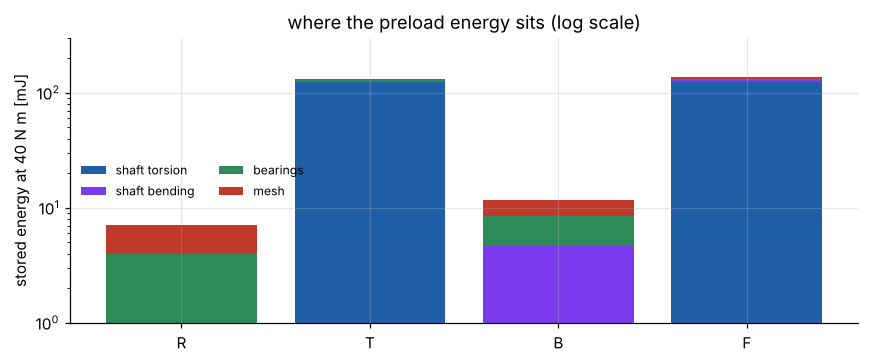

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.4))
keys = ["shaft torsion", "shaft bending", "bearings", "mesh"]
cols = [gd.C["blue"], gd.C["purple"], gd.C["green"], gd.C["red"]]
bottom = np.zeros(4)
for k_, c_ in zip(keys, cols):
    vals = np.array([splits[v][k_] for v in VARIANTS]) * 1e3
    ax.bar(list(VARIANTS), vals, bottom=bottom, color=c_, label=k_)
    bottom += vals
ax.set_ylabel("stored energy at 40 N m [mJ]"); ax.set_yscale("log"); ax.set_ylim(1, 300)
ax.legend(fontsize=8, ncol=2); ax.set_title("where the preload energy sits (log scale)")
plt.tight_layout()
for v in VARIANTS:
    tot = sum(splits[v].values())
    print(f"{v}: total {tot*1e3:7.2f} mJ -> " + ", ".join(f"{k_} {splits[v][k_]/tot*100:4.1f} %" for k_ in keys))

* The bearing reactions are identical in all four variants and equal the hand calculation.
* **Torsional** shaft flexibility dominates the input twist and the stored energy (T, F: about
  95 % of it sits in the shafts). The mesh holds 3 mJ in every variant.
* **Bending** flexibility adds only a few mJ of stored energy, but it moves the gear sideways by
  several µm and tilts it. A tilted gear loads one end of the face more than the other. ISO
  calls this the face-load factor $K_{H\beta}$. A planar mesh model can't see it; you need a
  sliced mesh (several springs across the face), as in the exercises.

## 4  Modes

Linearized on the drive flank, all modes below 15 kHz, coloured by the share of strain energy
in the mesh.

R:  9 modes < 15 kHz, lowest   584.6 Hz, most mesh-dominated    4656 Hz (43 % mesh)
T: 13 modes < 15 kHz, lowest   141.4 Hz, most mesh-dominated    7899 Hz (90 % mesh)
B: 21 modes < 15 kHz, lowest   238.2 Hz, most mesh-dominated    5363 Hz (57 % mesh)
F: 25 modes < 15 kHz, lowest   138.8 Hz, most mesh-dominated    8887 Hz (76 % mesh)


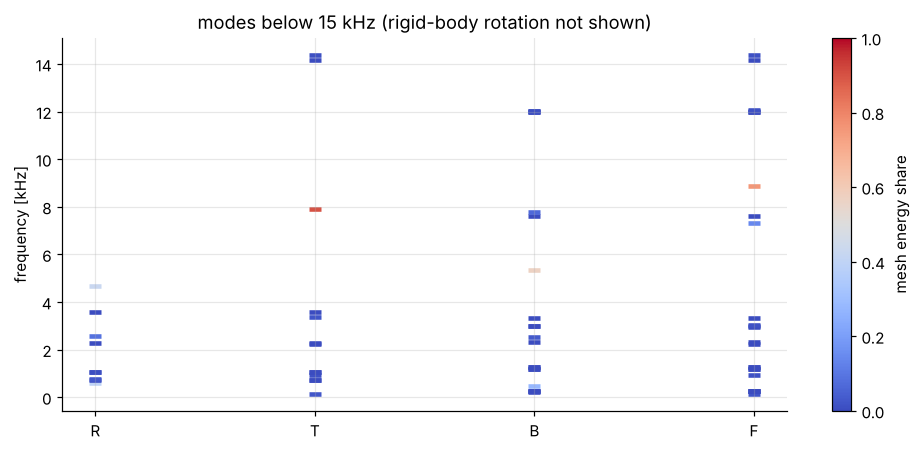

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.2))
modes = {}
for j, var in enumerate(VARIANTS):
    m, *_ = drivetrain(var)
    f, V = m.linear_modes()
    Km = m.mesh_stiffness_matrix(); _, K, _ = m.matrices()
    sel = (f > 1) & (f < 15e3)
    share = np.array([np.clip((V[:, i] @ Km @ V[:, i]) / (V[:, i] @ (K + Km) @ V[:, i]), 0, 1) for i in np.flatnonzero(sel)])
    modes[var] = (f[sel], share, V[:, sel], m)
    ax.scatter(np.full(sel.sum(), j), f[sel] / 1e3, c=share, cmap="coolwarm", vmin=0, vmax=1, s=60, marker="_", linewidths=3)
ax.set_xticks(range(4)); ax.set_xticklabels([f"{v}" for v in VARIANTS])
ax.set_ylabel("frequency [kHz]")
sm = plt.cm.ScalarMappable(cmap="coolwarm"); sm.set_clim(0, 1)
plt.colorbar(sm, ax=ax, label="mesh energy share")
ax.set_title("modes below 15 kHz (rigid-body rotation not shown)")
plt.tight_layout()
for var in VARIANTS:
    f_, sh_, *_ = modes[var]
    i = np.argmax(sh_)
    print(f"{var}: {len(f_):2d} modes < 15 kHz, lowest {f_[0]:7.1f} Hz, most mesh-dominated {f_[i]:7.0f} Hz ({sh_[i]*100:.0f} % mesh)")

* Torsional flexibility (T, F) brings in the **low drivetrain mode** (about 140 Hz): input
  and output inertia swinging against each other through the shafts. The mesh is just a stiff
  link in it.
* Bending flexibility (B, F) adds a forest of lateral modes from 240 Hz upwards: the overhung
  end discs on flexible shafts.
* The **most mesh-dominated mode** lies anywhere from about 4.7 kHz (R) to 8.9 kHz (F). It
  depends on how the gears are supported laterally and torsionally (notebook 05), so once
  shafts are in the model there is no single "mesh frequency" any more. In R the heavy
  overhung discs ride rigidly with the gears and pull it down.

Mode shapes of variant F: torsion angle and lateral amplitude along both shafts.

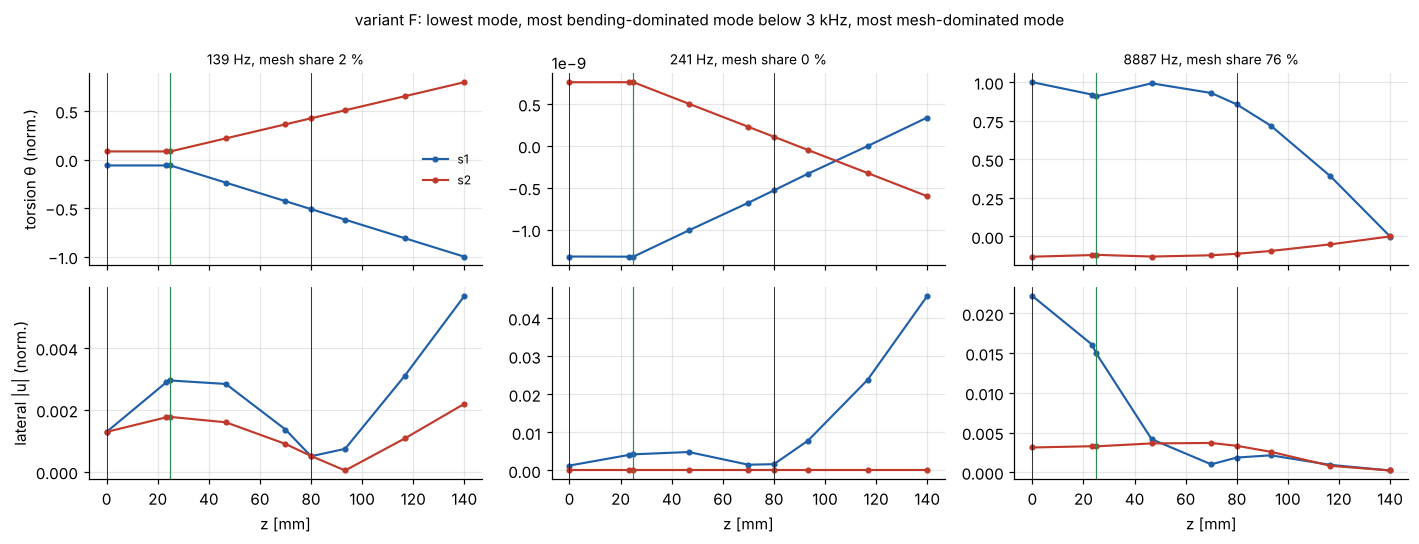

In [7]:
f_, sh_, V_, mF = modes["F"]
_, s1, s2, *_ = drivetrain("F")
bend_share = np.array([gd.element_energy(mF, s1, V_[:, i], "bending") + gd.element_energy(mF, s2, V_[:, i], "bending")
                       for i in range(len(f_))]) / (0.5 * (2 * np.pi * f_)**2)   # modes are mass-normalised
pick = [0, int(np.argmax(bend_share * (f_ < 3000))), int(np.argmax(sh_))]
fig, axs = plt.subplots(2, 3, figsize=(13, 5), sharex=True)
for c, i in enumerate(pick):
    v = V_[:, i]
    for s, col in [(s1, gd.C["blue"]), (s2, gd.C["red"])]:
        nn = range(len(s["z"]))
        th = np.array([v[mF.index(s["dof"](k, "th"))] for k in nn])
        lat = np.array([np.hypot(v[mF.index(s["dof"](k, "x"))], v[mF.index(s["dof"](k, "y"))]) for k in nn])
        axs[0, c].plot(s["z"] * 1e3, th / np.max(np.abs(v)), "-o", ms=3, color=col, label=s["name"])
        axs[1, c].plot(s["z"] * 1e3, lat / np.max(np.abs(v)), "-o", ms=3, color=col)
    axs[0, c].set_title(f"{f_[i]:.0f} Hz, mesh share {sh_[i]*100:.0f} %", fontsize=9)
    for a in axs[:, c]:
        a.axvline(25, color=gd.C["green"], lw=0.8); a.axvline(0, color="k", lw=0.5); a.axvline(80, color="k", lw=0.5)
    axs[1, c].set_xlabel("z [mm]")
axs[0, 0].set_ylabel("torsion θ (norm.)"); axs[1, 0].set_ylabel("lateral |u| (norm.)")
axs[0, 0].legend(fontsize=8)
plt.suptitle("variant F: lowest mode, most bending-dominated mode below 3 kHz, most mesh-dominated mode", fontsize=10)
plt.tight_layout()

## 5  Experiment A: release the wind-up through the backlash

This is your preload experiment at drivetrain scale. Clamp the output end, wind up the input end
with 40 N m (shafts, bearings and teeth all preloaded), then let go.

* **R (rigid shafts)**: only about 7 mJ is stored, in mesh and bearings. But gear 1 is now
  welded to the big input inertia, so after the push-off the *whole input side* flies across the
  backlash. The input angle becomes a slow triangle wave (constant-speed flights), with short,
  hard impacts at each end.
* **F (flexible shafts)**: about 20× more energy sits in the shaft twist. It comes back through
  the mesh at the 140 Hz drivetrain mode, so the torque through the teeth reverses every half
  period. At each reversal the light gears cross the gap on their own and chatter against the new
  flank until the shafts load them again: **clunk**.

R: reduced basis 11 vectors (modes < 20 kHz + static mesh/load shapes), energy residual 1.5e-07 V0


F: reduced basis 27 vectors (modes < 20 kHz + static mesh/load shapes), energy residual 3.8e-07 V0


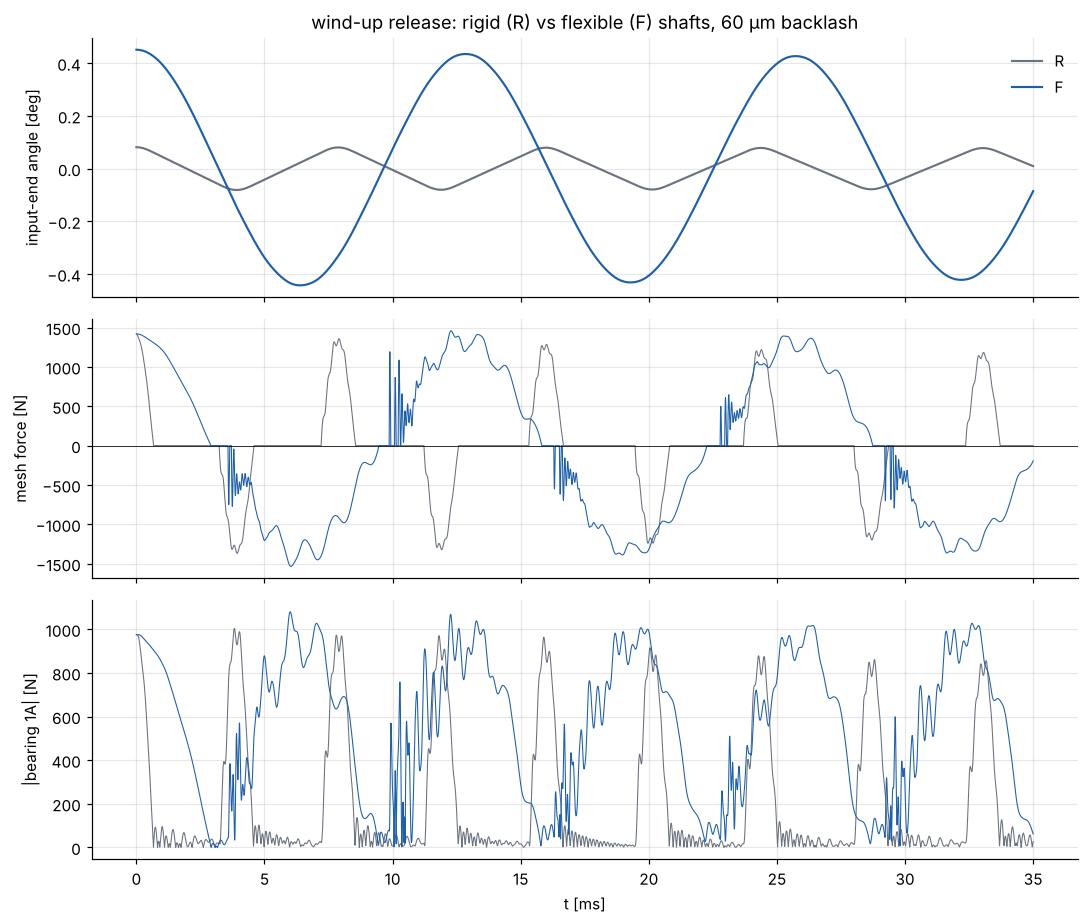

In [8]:
res = {}
for var in ["R", "F"]:
    m, s1, s2, end1, end2 = drivetrain(var)
    m.fix(end2)
    Q = np.zeros(m.n); Q[m.index(end1)] = T1
    q0 = m.static(Q)
    r = m.simulate(0.035, q0=q0, f_cut=F_CUT, method="RK45", rtol=1e-7, n_out=14000)
    res[var] = (r, m, s1, s2, end1)
    print(f"{var}: reduced basis {m._compiled['Phi'].shape[1]} vectors (modes < {F_CUT/1e3:.0f} kHz + static mesh/load shapes), "
          f"energy residual {np.max(np.abs(r.energy_residual))/r.V[0]:.1e} V0")

fig, ax = plt.subplots(3, 1, figsize=(10, 8.5), sharex=True)
for var, col in [("R", gd.C["grey"]), ("F", gd.C["blue"])]:
    r, m, s1, s2, end1 = res[var]
    ax[0].plot(r.t * 1e3, np.degrees(r[end1]), color=col, label=var)
    ax[1].plot(r.t * 1e3, r.mesh[0]["F"], color=col, lw=0.7, label=var)
    ax[2].plot(r.t * 1e3, np.hypot(*r.bearing["s1A"]), color=col, lw=0.7, label=var)
ax[0].set_ylabel("input-end angle [deg]"); ax[0].legend()
ax[1].set_ylabel("mesh force [N]"); ax[1].axhline(0, color="k", lw=0.5)
ax[2].set_ylabel("|bearing 1A| [N]"); ax[2].set_xlabel("t [ms]")
ax[0].set_title("wind-up release: rigid (R) vs flexible (F) shafts, 60 µm backlash")
plt.tight_layout()

F: 15 flank impacts in 35 ms, peak coast-flank force 1534 N, peak drive-flank force after release 1460 N (preload 1419 N)


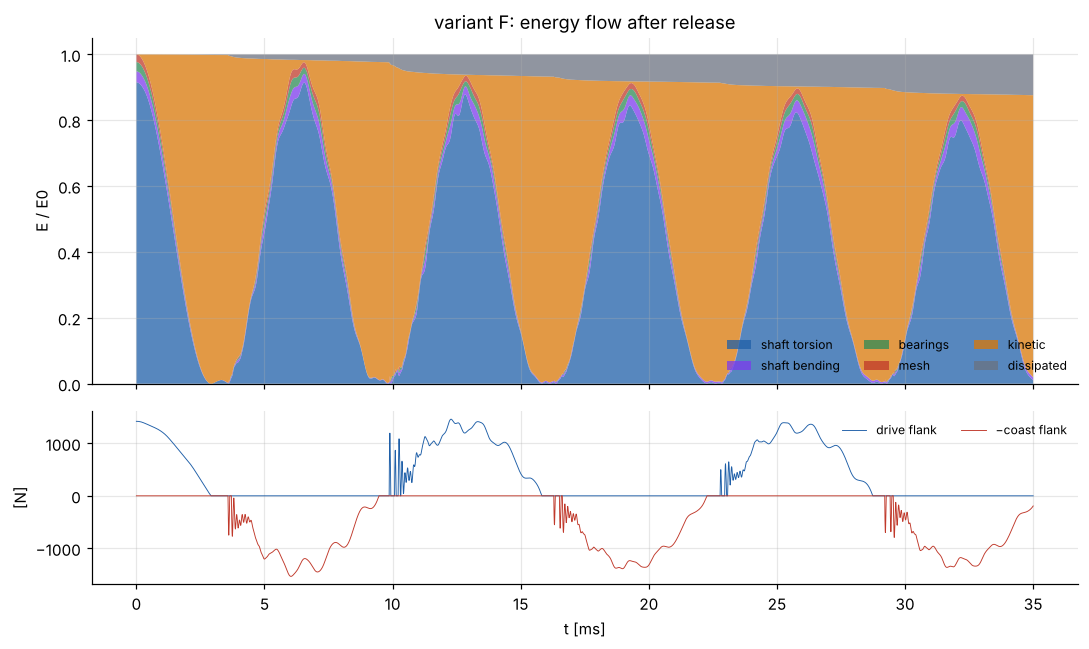

In [9]:
r, m, s1, s2, end1 = res["F"]
E = strain_split(m, s1, s2, r.q)
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
V0 = r.V[0]
ax[0].stackplot(r.t * 1e3, E["shaft torsion"] / V0, E["shaft bending"] / V0, E["bearings"] / V0, E["mesh"] / V0,
                r.T / V0, r.E_diss / V0,
                labels=["shaft torsion", "shaft bending", "bearings", "mesh", "kinetic", "dissipated"],
                colors=[gd.C["blue"], gd.C["purple"], gd.C["green"], gd.C["red"], gd.C["orange"], gd.C["grey"]], alpha=0.75)
ax[0].set_ylabel("E / E0"); ax[0].legend(ncol=3, fontsize=8, loc="lower right")
ax[0].set_title("variant F: energy flow after release")
mesh = r.mesh[0]
ax[1].plot(r.t * 1e3, mesh["Fd"], lw=0.6, label="drive flank")
ax[1].plot(r.t * 1e3, -mesh["Fr"], lw=0.6, label="−coast flank")
ax[1].set_ylabel("[N]"); ax[1].set_xlabel("t [ms]"); ax[1].legend(fontsize=8, ncol=2)
plt.tight_layout()
n_imp = np.sum(np.diff((mesh["Fr"] > 0).astype(int)) == 1) + np.sum(np.diff((mesh["Fd"] > 0).astype(int)) == 1)
print(f"F: {n_imp} flank impacts in 35 ms, peak coast-flank force {mesh['Fr'].max():.0f} N, "
      f"peak drive-flank force after release {mesh['Fd'][r.t > 1e-3].max():.0f} N (preload {F0:.0f} N)")

The energy plot shows the mechanism. Shaft-torsion energy (blue) turns into kinetic energy of
the big inertias and back at the drivetrain mode. Each time the torque through the mesh changes
sign, the gears separate, cross the gap and hit the other flank. The light gears rebound a few
times (the bursts in the force plot) before the shafts load them again, and each rebound costs a
little energy. The peak flank forces reach the static preload force. The mesh energy itself
(red) is a sliver: the teeth **carry** the energy, they don't store it.

The two variants fail differently. R gives rare, hard knocks at a rate set by flight time.
F gives a load reversal at the drivetrain frequency with a burst of small impacts at every
zero crossing. The second is the typical "clunk" signature on a real drivetrain at a
throttle tip-in or tip-out.

## 6  Experiment B: running at speed, rigid against flexible

Time-varying stiffness on, input end driven at constant speed (prescribed), output end with
the reaction torque $i\,T_1$ and its inertia. Start from the static equilibrium with the
rigid-body speeds, so the low drivetrain mode barely gets excited. Evaluate the last 10 mesh
cycles.

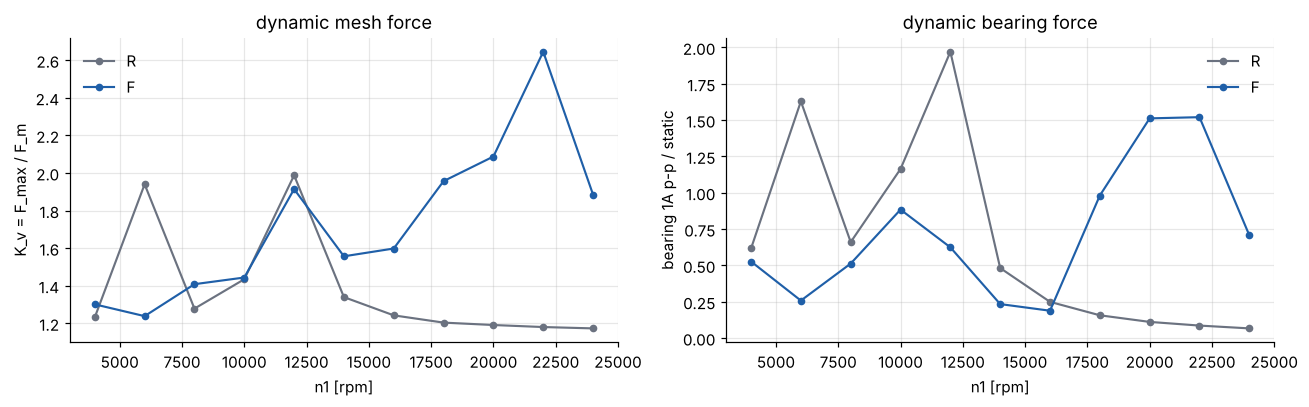

In [10]:
def run(var, n1):
    m, s1, s2, end1, end2 = drivetrain(var, stiffness="tv")
    W = n1 * 2 * np.pi / 60
    m.prescribe(end1, lambda t: W * t, lambda t: W, lambda t: 0.0)
    m.add_load(end2, lambda t, q, v: -gp.i * T1)
    Q = np.zeros(m.n); Q[m.index(end2)] = -gp.i * T1
    q0 = m.static(Q)
    v0 = np.zeros(m.n)
    for s, w in [(s1, W), (s2, W / gp.i)]:
        for k in range(len(s["z"])):
            v0[m.index(s["dof"](k, "th"))] = w
    fz = gp.f_mesh(n1)
    t_end = 30 / fz + 8e-3
    t_ev = np.linspace(t_end - 10 / fz, t_end, 501)
    return m.simulate(t_end, q0=q0, v0=v0, t_eval=t_ev, f_cut=F_CUT, method="RK45", rtol=1e-7)


speeds = np.linspace(4000, 24000, 11)
out = {}
for var in ["R", "F"]:
    Kv, Rb = [], []
    for n in speeds:
        r = run(var, n)
        Kv.append(r.mesh[0]["F"].max() / F0)
        Rb.append(np.ptp(np.hypot(*r.bearing["s1A"])) / np.hypot(RA_hand[0], RA_hand[1]))
    out[var] = (np.array(Kv), np.array(Rb))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for var, col in [("R", gd.C["grey"]), ("F", gd.C["blue"])]:
    ax[0].plot(speeds, out[var][0], "o-", ms=4, color=col, label=var)
    ax[1].plot(speeds, out[var][1], "o-", ms=4, color=col, label=var)
ax[0].set_ylabel("K_v = F_max / F_m"); ax[1].set_ylabel("bearing 1A p-p / static")
for a in ax:
    a.set_xlabel("n1 [rpm]"); a.legend()
ax[0].set_title("dynamic mesh force"); ax[1].set_title("dynamic bearing force")
plt.tight_layout()

Shaft flexibility changes *which* resonances lie in the speed range. Bending modes of the gear
node couple into the mesh along $\mathbf n_d$, and the bearing force is no longer a fixed
fraction of the tooth force. Whether flexible shafts help or hurt depends on the layout,
which is the reason to build this model instead of guessing.

## 7  Take-aways and outlook

* One assembler covers the whole series. Shafts, bearings and discs make up the linear
  structure; the nonlinear mesh couples it through one gradient vector per flank.
* Bearing reactions on a two-bearing shaft are **statically determinate**: identical for rigid
  and flexible shafts and equal to the hand calculation. Deflections, stored energy and
  dynamics are not.
* **Torsional** shaft flexibility stores most of the wind-up energy and sets the low drivetrain
  modes. With backlash, releasing it means repeated flank changes (clunk) driven by the
  shafts, not the teeth.
* **Bending** flexibility moves and tilts the gears. That shifts the mesh-dominated mode, changes
  the bearing-force spectrum and, beyond a planar model, the load distribution across the face.
* Model size: `simulate(f_cut=...)` keeps the modes below `f_cut` and adds **static shapes**
  for the mesh-force and load directions plus **constraint modes** for driven DOFs. Without the
  static shapes, the truncated model gets even the static tooth force wrong (for variant R it
  came out about 35 % low here). This is the idea behind **Craig–Bampton** reduction, the
  standard way MBS codes (Simpack, Adams) bring in FE components.

**Connections to the other work in this project:** the bearing DOFs here are exactly the
"radial bearing DOFs" planned as Stage 4 of the Python camtrain model. The torsional chain
(variant T) is the gear version of the crank-torsion root-cause model.

## Exercises

1. **Sliced mesh**: split the face into 5 slices, each a `GearMesh` at its own axial node
   (or at the gear node, with the slope DOFs adding $\pm z_i\,x'$ to the penetration). Show how
   shaft bending loads one end of the face ($K_{H\beta}$).
2. Move the gear to $z = 70$ mm (near bearing B). Which modes change most?
3. Experiment A with zero backlash (`backlash=0`). Does the clunk disappear? What remains?
4. Make the input a **torque** with a 2nd-order ripple (notebook 04, section 4) instead of a
   prescribed speed, and look for rattle at the gear while the shafts stay loaded.
5. Replace the bearings by a nonlinear (Hertzian, with clearance) bearing element in the
   style of `GearMesh`.